In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# Standard Library Imports

# ─────────────────────────────────────────────────────────────────────────────
# Third-Party Imports
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import List
from datetime import timedelta

# Define Seaborn style
def set_academic_style():
    
    # Color Universal Design Palette
    color_palette = [
        "#377eb8",  # azul
        "#ff7f00",  # naranja
        "#4daf4a",  # verde
        "#f781bf",  # rosa
        "#a65628",  # marrón
        "#984ea3",  # púrpura
        "#999999",  # gris
        "#e41a1c",  # rojo
        "#dede00"   # amarillo
    ]

    # Style
    sns.set(
        style="whitegrid",
        palette=color_palette,
        context="paper",
        font_scale=1.5
    )

    # Additional Matplotlib Config
    plt.rcParams.update({
        "figure.figsize": (10, 6),
        "axes.titlesize": 18,
        "axes.labelsize": 14,
        "axes.labelweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.6,
        "grid.linestyle": "--",
        "legend.fontsize": 12,
        "legend.title_fontsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "savefig.dpi": 300,
        "savefig.format": "pdf"
    })

set_academic_style()


# Input

In [2]:
def datasetsCreator(csv_files, calibrations):
    # Leer y procesar cada archivo
    datasets: List[pl.DataFrame] = []
    for filepath in csv_files:
        df: pl.DataFrame = pl.read_csv(filepath)
        df = df.with_columns([
            (
                (pl.col("timestamp") - pl.col("timestamp").min())
                .cast(pl.Duration("ns")) + pl.lit(0).cast(pl.Datetime("ns"))
            ).alias("timestamp"),
            pl.col("value").cast(pl.Int64)
        ])
        # Filter PTP metrics
        df_ptp = df.filter(
            pl.col("metric").str.contains("PPS") | 
            pl.col("metric").str.contains("offset")
            )

        # PTP Correspondence
        ptp_map = {
            "PPS_3_PPSAnalyzer": "TimeStick_hw_offset",
            "PPS_4_PPSAnalyzer": "Intel 710_hw_offset",
            "PPS_5_PPSAnalyzer": "Intel 810_hw_offset",
            "offset_TimeStick_PTP_Log": "TimeStick_sw_offset",
            "offset_Intel 710_PTP_Log": "Intel 710_sw_offset",
            "offset_Intel 810_PTP_Log": "Intel 810_sw_offset",
        }

        # Name Replacement
        df_ptp = df_ptp.with_columns(
            pl.col("metric").replace(ptp_map).alias("PTP_metric"),
            pl.col("value").alias("offset_ns")
        ).drop("metric", "value")

        # Hardware PTP Dataframe
        df_hw_ptp = df_ptp.filter(
            pl.col("PTP_metric").str.contains("hw")
        ).rename({
            "offset_ns": "offset_hw_ns",
            "PTP_metric":"PTP_client",
        }).with_columns(
            pl.col("PTP_client").replace(
                {
                    "TimeStick_hw_offset": "TimeStick",
                    "Intel 710_hw_offset": "Intel 710",
                    "Intel 810_hw_offset": "Intel 810",
                }
            )
        )
        
        df_hw_ptp_calibrated = df_hw_ptp.with_columns(
            pl.when(pl.col("PTP_client") == "TimeStick")
            .then(pl.col("offset_hw_ns") - calibrations[0])
            .otherwise(
                pl.when(pl.col("PTP_client") == "Intel 710")
                .then(pl.col("offset_hw_ns") - calibrations[1])
                .otherwise(
                    pl.col("offset_hw_ns") - calibrations[2]
                )    
            )
        )
        datasets.append(df_hw_ptp_calibrated)
    return datasets

def load_datasets(base_dir: str, prefix: str, durations: List[int], suffix: str, calibrations: List[int]) -> List[List[pl.DataFrame]]:
    all_datasets: List[List[pl.DataFrame]] = []
    for duration in durations:
        time_label = f"T{duration}"
        dir_path = Path(f"{base_dir}/{prefix}-{time_label}-{suffix}")
        pattern = f"{prefix}-{time_label}-{suffix}_*.csv"
        #print(pattern)
        csv_files: List[Path] = list(dir_path.glob(pattern))
        datasets: List[pl.DataFrame] = datasetsCreator(csv_files, calibrations)
        all_datasets.append(datasets)
    return all_datasets

# WE2

In [3]:
calibrations = [162, 325, -35]

# Traffic Model 1 (Little Packets majority)
we2_dataset_L25_75_SPTM = load_datasets("../output/Ly3_WE2", "Ly3_WE2_L25_75", [30], "TM1", calibrations)[0][0]

# Traffic Model 2 (Big Packets majority)
we2_dataset_L25_75_LPTM = load_datasets("../output/Ly3_WE2", "Ly3_WE2_L25_75", [30], "TM2", calibrations)[0][0]


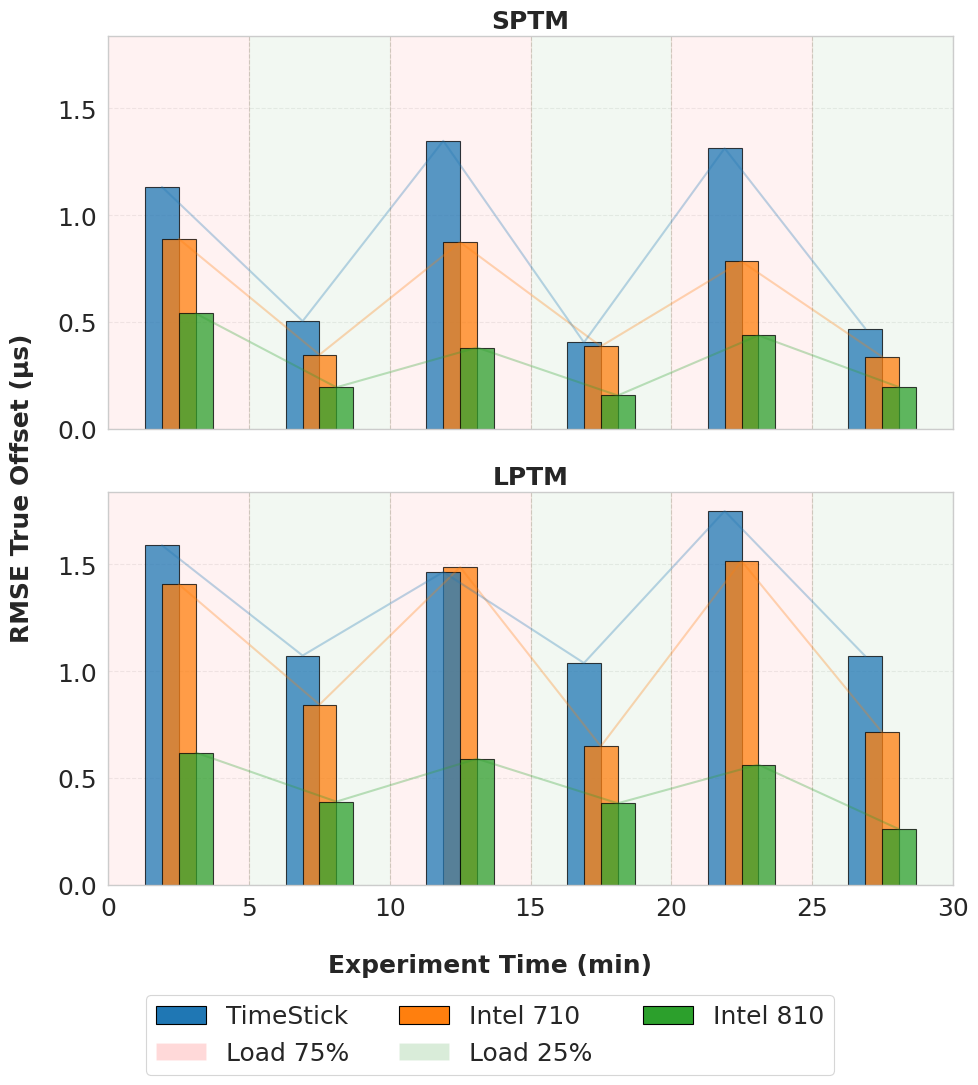

In [4]:

import polars as pl
import matplotlib.pyplot as plt
from datetime import timedelta
import numpy as np
from cycler import cycler
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# =====================================================
# Parámetros globales
# =====================================================
window = timedelta(minutes=5)
n_blocks = 6
bar_width = 1.2

# Orden lógico de los clientes
CLIENTS = ["TimeStick", "Intel 710", "Intel 810"]

# Offsets horizontales por cliente
client_offset = {
    "TimeStick": -0.6,
    "Intel 710":   0.0,
    "Intel 810":  +0.6,
}

# =====================================================
# Paleta de colores (tab10)
# =====================================================
palette = plt.cm.tab10.colors

client_colors = dict(zip(CLIENTS, palette))

# =====================================================
# Función común: RMS por ventanas
# =====================================================
def compute_rms(df: pl.DataFrame) -> pl.DataFrame:
    t0 = df["timestamp"].min()

    df = df.with_columns(
        (
            (pl.col("timestamp") - t0)
            .dt.total_seconds() / 60.0
        ).alias("t_min")
    )

    df_blocked = df.with_columns(
        (
            ((pl.col("timestamp") - t0)
             .dt.total_seconds() // window.total_seconds())
            .cast(pl.Int64)
            .alias("block")
        )
    ).filter(pl.col("block") < n_blocks)

    rms = (
        df_blocked
        .group_by(["PTP_client", "block"])
        .agg(
            rms=(pl.col("offset_hw_ns").pow(2).mean().sqrt())
        )
        .with_columns(
            (t0 + (pl.col("block") + 0.5) * window).alias("t_center"),
            pl.when(pl.col("block") % 2 == 0)
              .then(pl.lit("75%"))
              .otherwise(pl.lit("25%"))
              .alias("load"),
        )
        .with_columns(
            (
                (pl.col("t_center") - t0)
                .dt.total_seconds() / 60.0
            ).alias("t_min")
        )
    )

    return rms.sort(["PTP_client", "block"])

# =====================================================
# Cargar datasets
# =====================================================
rms_SPTM = compute_rms(we2_dataset_L25_75_SPTM)
rms_LPTM = compute_rms(we2_dataset_L25_75_LPTM)

# =====================================================
# Escala común eje Y
# =====================================================
y_max = max(
    rms_SPTM["rms"].max(),
    rms_LPTM["rms"].max(),
) * 1.05

y_min = 0.0

# =====================================================
# Figura
# =====================================================
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 10), sharex=True,
    gridspec_kw={"height_ratios": [1, 1]}
)

# Paleta como cycle (opcional pero elegante)
ax1.set_prop_cycle(cycler(color=palette[:len(CLIENTS)]))
ax2.set_prop_cycle(cycler(color=palette[:len(CLIENTS)]))

# =====================================================
# SUBPLOT 1 — SPTM
# =====================================================
for block in range(n_blocks):
    block_df = rms_SPTM.filter(pl.col("block") == block).sort("rms", descending=True)

    for row in block_df.iter_rows(named=True):
        client = row["PTP_client"]
        x = row["t_min"] + client_offset[client]

        ax1.bar(
            x,
            row["rms"],
            width=bar_width,
            color=client_colors[client],
            alpha=0.75,
            edgecolor="black",
            zorder=2,
        )

# Líneas suaves
for g in rms_SPTM.partition_by("PTP_client", as_dict=False):
    client = g["PTP_client"][0]
    ax1.plot(
        g["t_min"].to_numpy() + client_offset[client],
        g["rms"].to_numpy(),
        color=client_colors[client],
        linewidth=1.5,
        alpha=0.3,
        zorder=3,
    )

# Bandas de carga
for i in range(n_blocks):
    ax1.axvspan(
        i * 5, (i + 1) * 5,
        color="red" if i % 2 == 0 else "green",
        alpha=0.05,
        zorder=1,
    )

#ax1.set_ylabel("RMS offset (ns)")
ax1.set_title("SPTM", fontsize=18, fontweight='bold')
ax1.grid(axis="y", alpha=0.3)

# =====================================================
# SUBPLOT 2 — LPTM
# =====================================================
for block in range(n_blocks):
    block_df = rms_LPTM.filter(pl.col("block") == block).sort("rms", descending=True)

    for row in block_df.iter_rows(named=True):
        client = row["PTP_client"]
        x = row["t_min"] + client_offset[client]

        ax2.bar(
            x,
            row["rms"],
            width=bar_width,
            color=client_colors[client],
            alpha=0.75,
            edgecolor="black",
            zorder=2,
        )

# Líneas suaves
for g in rms_LPTM.partition_by("PTP_client", as_dict=False):
    client = g["PTP_client"][0]
    ax2.plot(
        g["t_min"].to_numpy() + client_offset[client],
        g["rms"].to_numpy(),
        color=client_colors[client],
        linewidth=1.5,
        alpha=0.3,
        zorder=3,
    )

# Bandas de carga
for i in range(n_blocks):
    ax2.axvspan(
        i * 5, (i + 1) * 5,
        color="red" if i % 2 == 0 else "green",
        alpha=0.05,
        zorder=1,
    )

#ax2.set_ylabel("RMS offset (ns)")
ax2.set_title("LPTM", fontsize=18, fontweight='bold')
ax2.grid(axis="y", alpha=0.3)

# =====================================================
# Eje X compartido
# =====================================================
ax2.set_xticks(np.arange(0, n_blocks * 5 + 1, 5))
ax2.set_xlim(0, n_blocks * 5)
ax1.tick_params(axis='y', labelsize=18)
ax2.tick_params(axis='y', labelsize=18)
ax1.tick_params(axis='x', labelsize=18)
ax2.tick_params(axis='x', labelsize=18)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y/1000}"))
ax2.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y/1000}"))

ax1.set_ylim(y_min, y_max)
ax2.set_ylim(y_min, y_max)
fig.supxlabel("Experiment Time (min)", fontsize=18, fontweight='bold')
fig.supylabel("RMSE True Offset (µs)", fontsize=18, fontweight='bold')

# =====================================================
# Leyenda (una sola vez)
# =====================================================

legend_elements = [
    Patch(facecolor=client_colors["TimeStick"], label="TimeStick", edgecolor="black"),
    Patch(facecolor="red",   alpha=0.15, label="Load 75%"),
    Patch(facecolor=client_colors["Intel 710"],  label="Intel 710", edgecolor="black"),
    Patch(facecolor="green", alpha=0.15, label="Load 25%"),
    Patch(facecolor=client_colors["Intel 810"],  label="Intel 810", edgecolor="black"),
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=3,
    frameon=True,
    fontsize=18
)

plt.tight_layout()
plt.savefig("Experiment2.pdf", format="pdf", bbox_inches='tight', pad_inches=0.05)

